In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Load the dataset directly from a public CSV
url = "https://raw.githubusercontent.com/abcom-mltutorials/mall/main/Mall_Customers.csv"

df = pd.read_csv(url)

# Display the first five rows
display(df.head())

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Dataset shape: (200, 5)

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Statistical summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


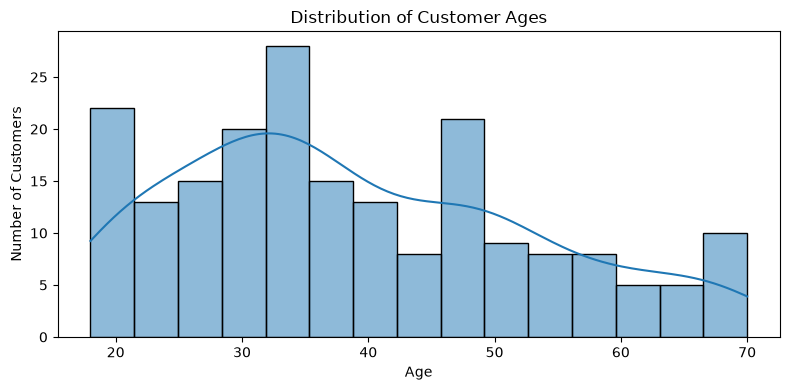

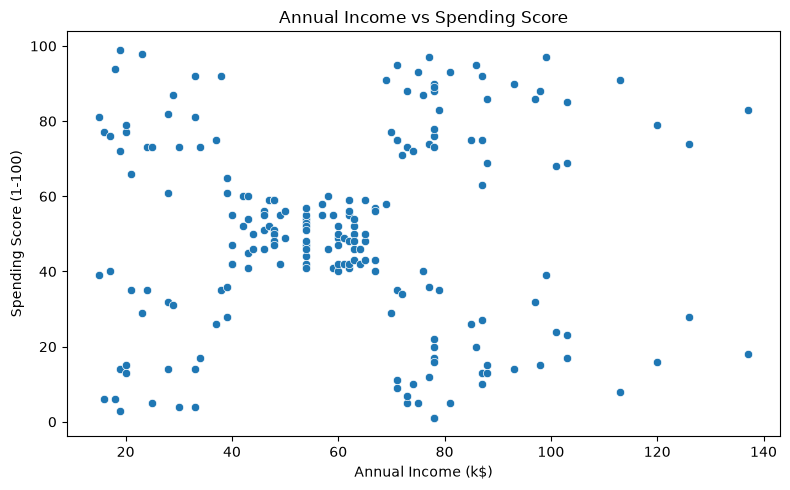

In [4]:
# Distribution of customer ages
plt.figure(figsize=(8, 4))
sns.histplot(df["Age"], bins=15, kde=True)
plt.title("Distribution of Customer Ages")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Annual income versus spending score
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)"
)
plt.title("Annual Income vs Spending Score")
plt.tight_layout()
plt.show()

In [5]:
# Select features for customer segmentation
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Standardise the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features selected:", X.columns.tolist())
print("Number of customers:", X.shape[0])
print("Data standardised successfully!")

Features selected: ['Annual Income (k$)', 'Spending Score (1-100)']
Number of customers: 200
Data standardised successfully!


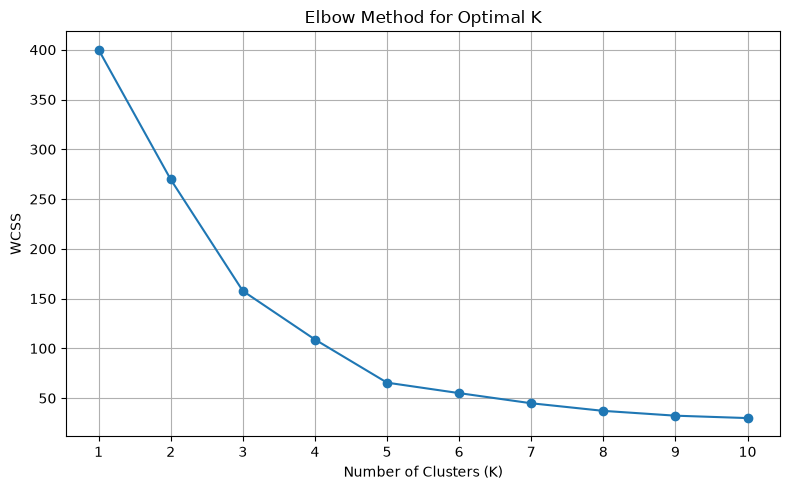

In [6]:
# Calculate WCSS for different numbers of clusters
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
# Train the model with 5 clusters
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")
print("\nCustomers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

K-Means clustering completed!

Customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


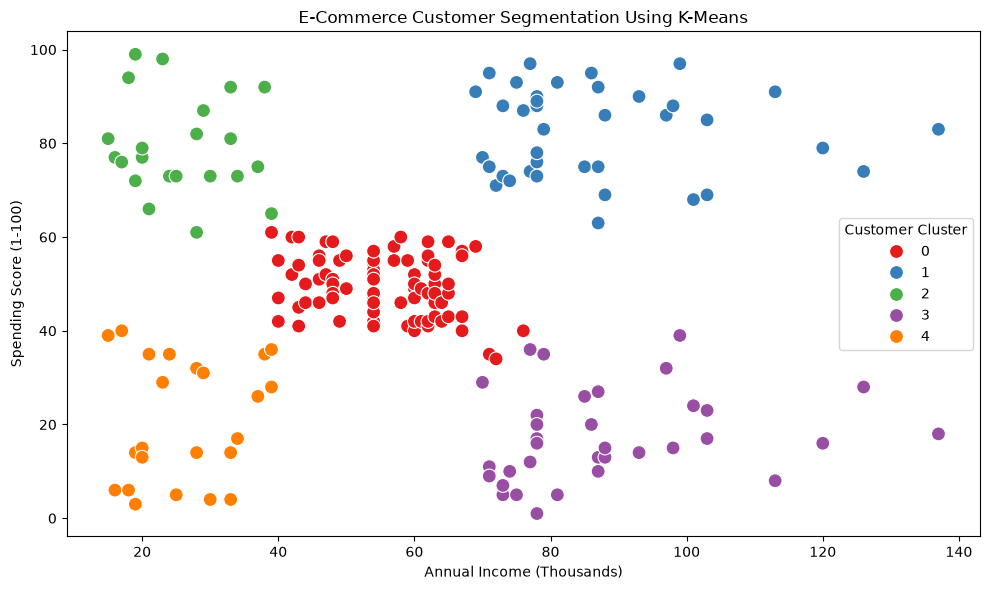

In [8]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set1",
    s=100
)

plt.title("E-Commerce Customer Segmentation Using K-Means")
plt.xlabel("Annual Income (Thousands)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Customer Cluster")
plt.tight_layout()
plt.show()

In [9]:
score = silhouette_score(X_scaled, df["Cluster"])

print(f"Silhouette Score: {score:.3f}")

Silhouette Score: 0.555


In [10]:
# Summarise the characteristics of each cluster
cluster_summary = df.groupby("Cluster").agg(
    Number_of_Customers=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

display(cluster_summary)

,Number_of_Customers,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


In [13]:
# Display cluster characteristics
print("CUSTOMER SEGMENT ANALYSIS\n")

for cluster in sorted(df["Cluster"].unique()):
    group = df[df["Cluster"] == cluster]

    income = group["Annual Income (k$)"].mean()
    spending = group["Spending Score (1-100)"].mean()

    print(f"Cluster {cluster}")
    print(f"  Number of customers: {len(group)}")
    print(f"  Average annual income: ${income:.2f}k")
    print(f"  Average spending score: {spending:.2f}")

    if income >= 60 and spending >= 60:
        print("  Segment: High-Income, High-Spending Customers")
    elif income >= 60 and spending < 40:
        print("  Segment: High-Income, Low-Spending Customers")
    elif income < 40 and spending >= 60:
        print("  Segment: Lower-Income, High-Spending Customers")
    elif income < 40 and spending < 40:
        print("  Segment: Lower-Income, Low-Spending Customers")
    else:
        print("  Segment: Moderate or Mixed Spending Behaviour")

    print()

CUSTOMER SEGMENT ANALYSIS

Cluster 0
  Number of customers: 81
  Average annual income: $55.30k
  Average spending score: 49.52
  Segment: Moderate or Mixed Spending Behaviour

Cluster 1
  Number of customers: 39
  Average annual income: $86.54k
  Average spending score: 82.13
  Segment: High-Income, High-Spending Customers

Cluster 2
  Number of customers: 22
  Average annual income: $25.73k
  Average spending score: 79.36
  Segment: Lower-Income, High-Spending Customers

Cluster 3
  Number of customers: 35
  Average annual income: $88.20k
  Average spending score: 17.11
  Segment: High-Income, Low-Spending Customers

Cluster 4
  Number of customers: 23
  Average annual income: $26.30k
  Average spending score: 20.91
  Segment: Lower-Income, Low-Spending Customers



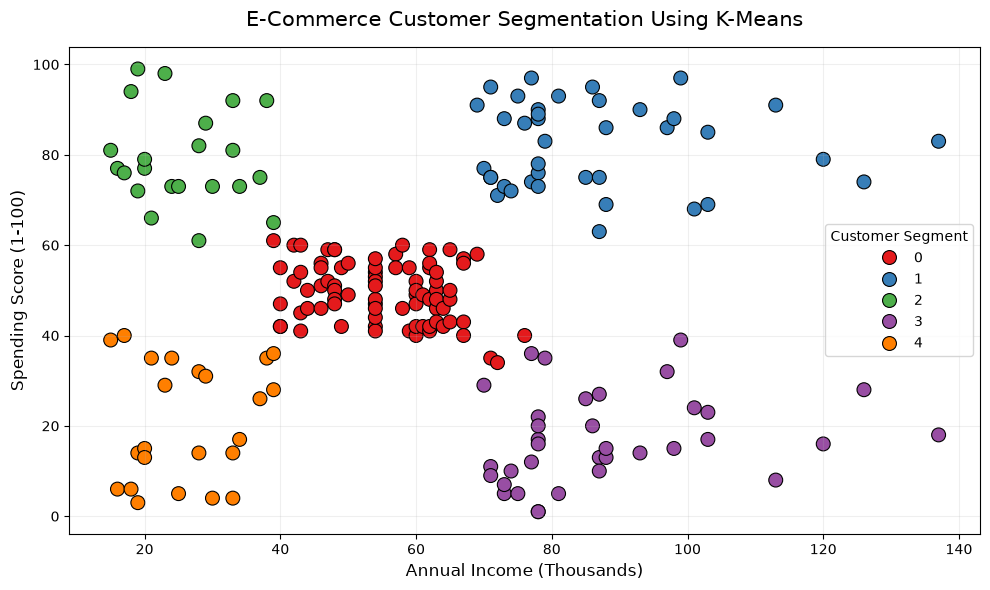

Graph saved as customer_segmentation.png


In [14]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set1",
    s=100,
    edgecolor="black"
)

plt.title(
    "E-Commerce Customer Segmentation Using K-Means",
    fontsize=15,
    pad=15
)
plt.xlabel("Annual Income (Thousands)", fontsize=12)
plt.ylabel("Spending Score (1-100)", fontsize=12)
plt.legend(title="Customer Segment")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "customer_segmentation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved as customer_segmentation.png")

In [15]:
# Save the customer data with cluster assignments
df.to_csv("segmented_customers.csv", index=False)

# Save the cluster summary
cluster_summary.to_csv("cluster_summary.csv")

print("Files saved successfully!")
print("1. customer_segmentation.png")
print("2. segmented_customers.csv")
print("3. cluster_summary.csv")

Files saved successfully!
1. customer_segmentation.png
2. segmented_customers.csv
3. cluster_summary.csv


In [16]:
import os
print(os.getcwd())

/home/padmashree-s-s/AI_ML_Project
